# King County house prices: regression homework
Assumed: primary metric RMSE (USD); secondary WAPE, RMSLE, MAE, R2. Assumed: costly errors are large dollar misses on expensive homes and systematic over/under-prediction; no asymmetric loss.
Target: sale `price` in USD of a house. Order deviation: CLAUDE.md says split first then look, so the test set is locked and folds drawn before EDA (EDA uses dev only).

In [1]:
import time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
warnings.filterwarnings("ignore")
T0 = time.time()
SEED = 0
np.random.seed(SEED)
raw = fetch_openml(data_id=42092, as_frame=True).frame
raw["date"] = pd.to_datetime(raw["date"], format="%Y%m%dT%H%M%S")
raw["zipcode"] = raw["zipcode"].astype(str)
print("shape", raw.shape, "NaN total", int(raw.isna().sum().sum()))
print("dates", raw.date.min().date(), raw.date.max().date())

shape (21613, 20) NaN total 0
dates 2014-05-02 2015-05-27


## Split first
Assumed: property key = (lat, long, sqft_living, sqft_lot, yr_built, zipcode); a property is assigned to one time chunk by its LAST sale date (all its sales stay together). Reason: with the first-sale date a resale in May 2015 would land in an early training chunk, i.e. training rows later than validation rows (this happened in my first draft; chunk ranges overlapped).
Assumed: locked test = last 15% of rows by property last-sale date. Dev is cut into 4 chunks by rows; fold k trains on chunks 0..k and validates on chunk k+1 (3 expanding-window folds). Chunk 0 is never validated.

In [2]:
KEY = ["lat", "long", "sqft_living", "sqft_lot", "yr_built", "zipcode"]
raw["gid"] = raw.groupby(KEY).ngroup()
g = raw.groupby("gid").agg(first=("date", "max"), n=("date", "size")).sort_values(["first"]).reset_index()
g["cum"] = g["n"].cumsum() / g["n"].sum()
print("properties", len(g), "| rows in multi-sale properties", int(g.n[g.n > 1].sum()), "in", int((g.n > 1).sum()), "properties")
test_gids = set(g.gid[g.cum > 0.85])
raw["is_test"] = raw.gid.isin(test_gids)
dev = raw[~raw.is_test].copy()
test = raw[raw.is_test].copy()      # locked: not touched until the final test section
# chunks on dev, by property last-sale date
gd = g[~g.gid.isin(test_gids)].copy()
gd["chunk"] = np.minimum((gd["n"].cumsum() / gd["n"].sum() * 4).apply(np.ceil).astype(int) - 1, 3)
dev["chunk"] = dev.gid.map(gd.set_index("gid")["chunk"])
assert not set(dev.gid) & set(test.gid)
print("dev", dev.shape, dev.date.min().date(), dev.date.max().date())
print("test (locked)", test.shape, test.date.min().date(), test.date.max().date())
print(dev.groupby("chunk").agg(rows=("date", "size"), start=("date", "min"), end=("date", "max")))

properties 21416 | rows in multi-sale properties 392 in 195 properties
dev (18371, 23) 2014-05-02 2015-03-26
test (locked) (3242, 22) 2014-05-23 2015-05-27
       rows      start        end
chunk                            
0      4592 2014-05-02 2014-07-10
1      4593 2014-05-05 2014-09-22
2      4593 2014-05-06 2014-12-12
3      4593 2014-05-05 2015-03-26


## EDA on dev only, then cleaning
Cleaning rules are row-level and use no target statistics, so applying them to both dev and test is not leakage.

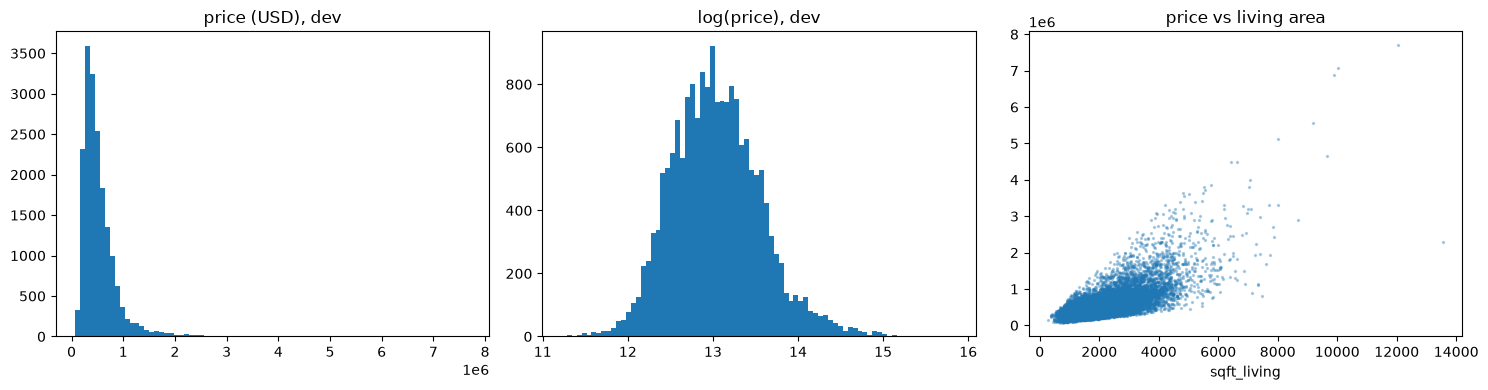

skew price 4.04 skew log price 0.43
share > 1M USD 0.067 median 449950.0 mean 537276
yr_renovated==0 share 0.956 | bedrooms>=10 rows: 5 max 33


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(dev.price, bins=80); ax[0].set_title("price (USD), dev")
ax[1].hist(np.log(dev.price), bins=80); ax[1].set_title("log(price), dev")
ax[2].scatter(dev.sqft_living, dev.price, s=2, alpha=.3); ax[2].set_xlabel("sqft_living"); ax[2].set_title("price vs living area")
plt.tight_layout(); plt.show()
from scipy.stats import skew
print("skew price", round(skew(dev.price), 2), "skew log price", round(skew(np.log(dev.price)), 2))
print("share > 1M USD", round((dev.price > 1e6).mean(), 3), "median", dev.price.median(), "mean", round(dev.price.mean()))
print("yr_renovated==0 share", round((dev.yr_renovated == 0).mean(), 3), "| bedrooms>=10 rows:", int((dev.bedrooms >= 10).sum()), "max", dev.bedrooms.max())

In [4]:
n0 = len(dev)
# 1) bedrooms == 33 with 1620 sqft: almost surely a typo for 3; drop (one row, rule not target-based)
bad = dev.bedrooms >= 30
print("rows with bedrooms>=30 in dev:", int(bad.sum()), dev.loc[bad, ["bedrooms", "sqft_living", "price"]].to_dict("records"))
dev = dev[~bad].copy(); test = test[test.bedrooms < 30].copy()
# 2) yr_renovated == 0 means never renovated -> flag, not a year (done in features)
# 3) zipcode is a category (string), never a number
# 4) other outliers (price>5M, 10 bedrooms) kept: real sales, trees are robust, log target tames the tail
print("dev rows", n0, "->", len(dev), "| test rows", len(test))

rows with bedrooms>=30 in dev: 1 [{'bedrooms': 33, 'sqft_living': 1620, 'price': 640000.0}]
dev rows 18371 -> 18370 | test rows 3242


In [5]:
FOLDS = []
for k in range(3):
    tr = dev.index[dev.chunk <= k]; va = dev.index[dev.chunk == k + 1]
    assert not set(dev.loc[tr, "gid"]) & set(dev.loc[va, "gid"])
    FOLDS.append((tr, va))
    print(f"fold {k}: train {len(tr)} ({dev.loc[tr,'date'].min().date()}..{dev.loc[tr,'date'].max().date()}) | val {len(va)} ({dev.loc[va,'date'].min().date()}..{dev.loc[va,'date'].max().date()})")
    print(f"   val rows dated before train max date: {(dev.loc[va,'date'] <= dev.loc[tr,'date'].max()).sum()} (early sales of resold properties)")
print("val index ids unique across folds:", len(set().union(*[set(v) for _, v in FOLDS])) == sum(len(v) for _, v in FOLDS))

fold 0: train 4591 (2014-05-02..2014-07-10) | val 4593 (2014-05-05..2014-09-22)
   val rows dated before train max date: 9 (early sales of resold properties)
fold 1: train 9184 (2014-05-02..2014-09-22) | val 4593 (2014-05-06..2014-12-12)
   val rows dated before train max date: 79 (early sales of resold properties)
fold 2: train 13777 (2014-05-02..2014-12-12) | val 4593 (2014-05-05..2015-03-26)
   val rows dated before train max date: 115 (early sales of resold properties)
val index ids unique across folds: True


## Baselines and models (same folds, no tuning)
Assumed: tree models get `zipcode` as an integer code (arbitrary order, trees can split it); the linear model gets one-hot zip + log target. Predictions of log models are exp(.) back to USD, no smearing correction, and the sum(pred)/sum(actual) ratio shows the resulting bias. RMSLE clips predictions at 1 USD.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

NUM = ["bedrooms","bathrooms","sqft_living","sqft_lot","floors","waterfront","view","condition","grade",
       "sqft_above","sqft_basement","yr_built","lat","long","sqft_living15","sqft_lot15","age","renovated"]
def feats(df):
    X = df[NUM[:16]].copy()
    X["age"] = df.date.dt.year - df.yr_built
    X["renovated"] = (df.yr_renovated > 0).astype(int)
    X["zipcode"] = df.zipcode
    return X

def rmse(y, p): return float(np.sqrt(np.mean((y - p) ** 2)))
def metrics(y, p):
    p = np.asarray(p, float); y = np.asarray(y, float)
    return dict(RMSE=rmse(y, p), MAE=float(np.mean(np.abs(y - p))), WAPE=float(np.abs(y - p).sum() / y.sum()),
                RMSLE=float(np.sqrt(np.mean((np.log1p(np.clip(p, 1, None)) - np.log1p(y)) ** 2))),
                R2=float(1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()), BIAS=float(p.sum() / y.sum()))

def fp_mean(Xtr, ytr, Xva):  return np.full(len(Xva), ytr.mean())
def fp_zipmed(Xtr, ytr, Xva):
    med = ytr.groupby(Xtr.zipcode).median()
    return Xva.zipcode.map(med).fillna(ytr.median()).values
def fp_linear(Xtr, ytr, Xva):
    num = [c for c in Xtr.columns if c != "zipcode"]
    pre = ColumnTransformer([("n", StandardScaler(), num), ("z", OneHotEncoder(handle_unknown="ignore"), ["zipcode"])])
    m = make_pipeline(pre, Ridge(alpha=1.0)).fit(Xtr, np.log(ytr))
    return np.exp(m.predict(Xva))
def _codes(Xtr, Xva):
    cats = {z: i for i, z in enumerate(sorted(Xtr.zipcode.unique()))}
    a, b = Xtr.copy(), Xva.copy()
    a["zipcode"] = a.zipcode.map(cats); b["zipcode"] = b.zipcode.map(cats).fillna(-1)
    return a.astype(float), b.astype(float)
def fp_tree(Xtr, ytr, Xva):
    a, b = _codes(Xtr, Xva); return DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=SEED).fit(a, ytr).predict(b)
def fp_rf(Xtr, ytr, Xva):
    a, b = _codes(Xtr, Xva); return RandomForestRegressor(n_estimators=100, min_samples_leaf=3, n_jobs=-1, random_state=SEED).fit(a, ytr).predict(b)
def fp_xgb(Xtr, ytr, Xva):
    a, b = _codes(Xtr, Xva)
    return XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, n_jobs=4, random_state=SEED).fit(a, ytr).predict(b)

MODELS = {"mean": fp_mean, "zip_median": fp_zipmed, "linear_log_zip": fp_linear, "tree": fp_tree, "rf": fp_rf, "xgb": fp_xgb}
Xdev, ydev = feats(dev), dev.price
OOF, rows = {}, []
for name, fn in MODELS.items():
    oof = pd.Series(np.nan, index=dev.index)
    for k, (tr, va) in enumerate(FOLDS):
        p = fn(Xdev.loc[tr], ydev.loc[tr], Xdev.loc[va]); oof.loc[va] = p
        rows.append(dict(model=name, fold=k, **metrics(ydev.loc[va], p)))
    OOF[name] = oof
res = pd.DataFrame(rows)
agg = res.groupby("model").agg(["mean", "std"]).drop(columns="fold")
tab = pd.DataFrame({m: agg[m]["mean"].map("{:,.3f}".format) + " +- " + agg[m]["std"].map("{:,.3f}".format) for m in ["RMSE","MAE","WAPE","RMSLE","R2","BIAS"]}).loc[list(MODELS)]
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
print(tab.to_string())
print("BIAS = sum(pred)/sum(actual). Fold sizes:", [len(v) for _, v in FOLDS])
BEST = res.groupby("model").RMSE.mean().idxmin()
print("best by mean CV RMSE:", BEST)

                                     RMSE                       MAE            WAPE           RMSLE               R2            BIAS
model                                                                                                                               
mean            361,400.493 +- 10,978.073  236,224.517 +- 2,970.087  0.446 +- 0.011  0.559 +- 0.015  -0.003 +- 0.001  1.039 +- 0.004
zip_median      287,473.677 +- 11,937.921  153,747.900 +- 2,073.833  0.290 +- 0.005  0.366 +- 0.008   0.365 +- 0.015  0.910 +- 0.017
linear_log_zip   139,805.436 +- 3,088.066   74,197.331 +- 3,243.780  0.140 +- 0.008  0.184 +- 0.014   0.850 +- 0.009  0.979 +- 0.017
tree             188,751.309 +- 6,988.104   98,188.302 +- 1,262.692  0.185 +- 0.003  0.233 +- 0.005   0.726 +- 0.018  0.993 +- 0.011
rf               134,602.095 +- 7,242.625   70,421.385 +- 1,425.803  0.133 +- 0.003  0.179 +- 0.008   0.860 +- 0.016  0.990 +- 0.013
xgb              119,588.238 +- 5,631.121   64,785.805 +- 1,705.484  

## Diagnostics on the best model's out-of-fold predictions
OOF = the three validation chunks (chunk 0 has no OOF prediction).

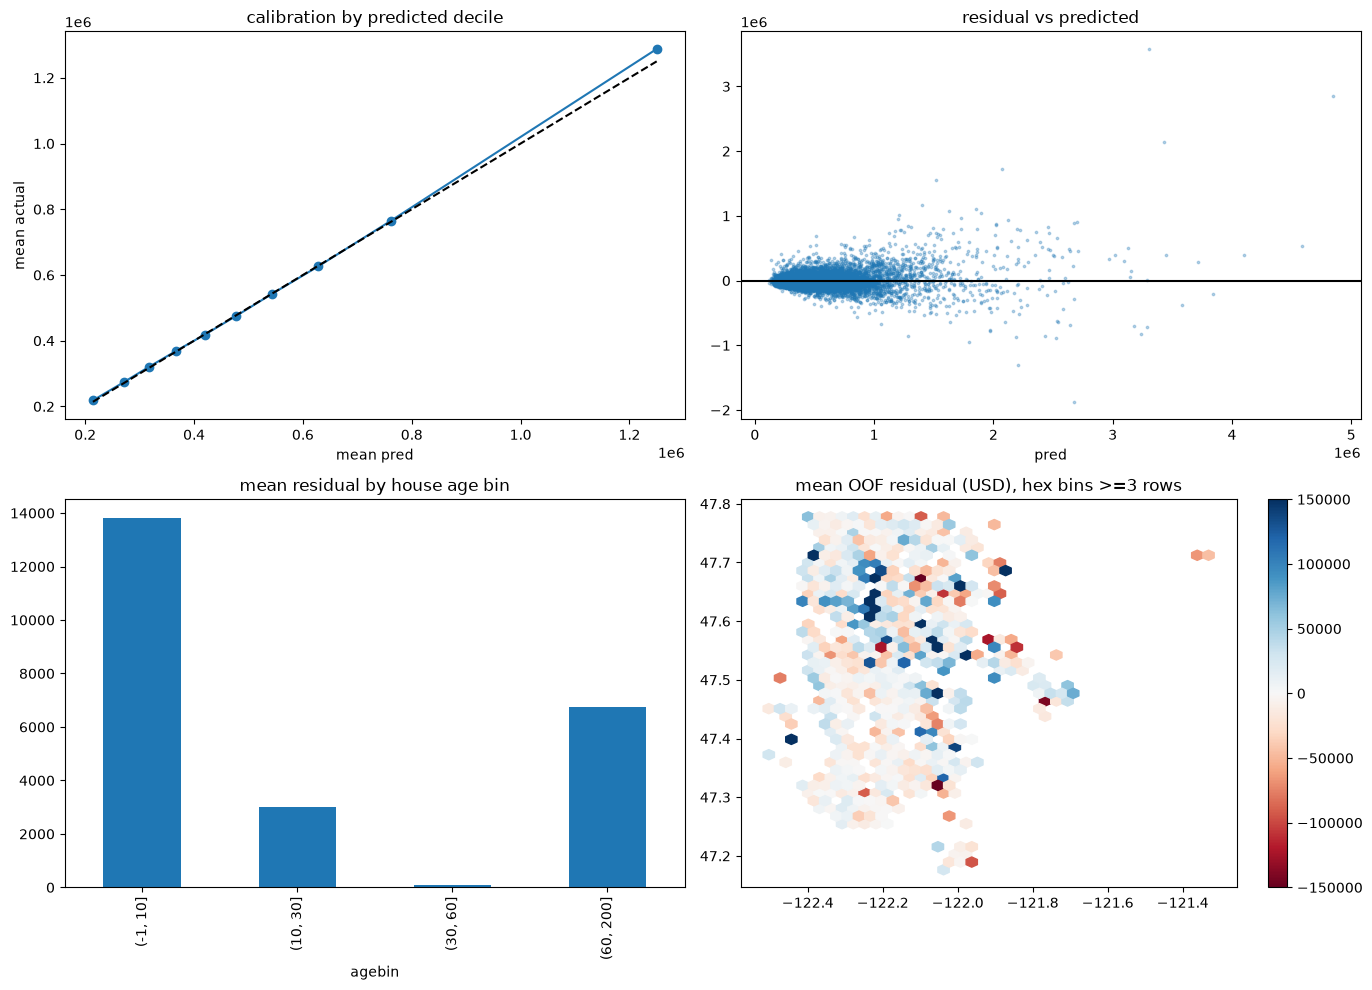

            pred       actual     n  ratio
dec                                       
0     214130.836   218324.858  1378  1.020
1     270800.515   273773.373  1378  1.011
2     316865.395   320198.610  1378  1.011
3     366446.691   368449.791  1378  1.005
4     419761.355   418586.332  1378  0.997
5     477280.830   475338.933  1377  0.996
6     543036.227   542396.231  1378  0.999
7     628059.317   626181.413  1378  0.997
8     761225.377   764516.729  1378  1.004
9    1250050.514  1287740.347  1378  1.030
              n     bias      rmse
agebin                            
(-1, 10]   2199  13824.0  119657.0
(10, 30]   3136   3012.0  134973.0
(30, 60]   4677     80.0   97201.0
(60, 200]  3760   6764.0  130916.0
          n     bias
pband               
Q1     3465 -19204.0
Q2     3443  -8729.0
Q3     3436  -1260.0
Q4     3435  48577.0
zip bias, 5 lowest / 5 highest (n>=40):
         size     mean
zipcode               
98108     112 -35378.0
98014      82 -34333.0
98005     113 -1

corr(residual, mean residual of 10 nearest other properties) = 0.212
corr(|resid|, pred) = 0.563 | share of residuals >0 = 0.499


In [7]:
va_idx = np.concatenate([v for _, v in FOLDS])
d = dev.loc[va_idx].copy(); d["pred"] = OOF[BEST].loc[va_idx]; d["res"] = d.price - d.pred
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
# 1 calibration by decile of prediction
d["dec"] = pd.qcut(d.pred, 10, labels=False)
cal = d.groupby("dec").agg(pred=("pred", "mean"), actual=("price", "mean"), n=("price", "size"))
cal["ratio"] = cal.actual / cal.pred
ax[0,0].plot(cal.pred, cal.actual, "o-"); ax[0,0].plot(cal.pred, cal.pred, "k--"); ax[0,0].set_title("calibration by predicted decile"); ax[0,0].set_xlabel("mean pred"); ax[0,0].set_ylabel("mean actual")
# 2 residual vs predicted
ax[0,1].scatter(d.pred, d.res, s=3, alpha=.3); ax[0,1].axhline(0, c="k"); ax[0,1].set_title("residual vs predicted"); ax[0,1].set_xlabel("pred")
# 3 segments: age bins
d["agebin"] = pd.cut(d.date.dt.year - d.yr_built, [-1, 10, 30, 60, 200])
seg = d.groupby("agebin").agg(n=("res", "size"), bias=("res", "mean"), rmse=("res", lambda r: np.sqrt((r**2).mean())))
seg.plot.bar(y="bias", ax=ax[1,0], legend=False); ax[1,0].set_title("mean residual by house age bin")
# 4 map
hb = ax[1,1].hexbin(d.long, d.lat, C=d.res, reduce_C_function=np.mean, gridsize=40, cmap="RdBu", vmin=-150000, vmax=150000, mincnt=3)
plt.colorbar(hb, ax=ax[1,1]); ax[1,1].set_title("mean OOF residual (USD), hex bins >=3 rows")
plt.tight_layout(); plt.show()
print(cal.round(3).to_string())
print(seg.round(0).to_string())
d["pband"] = pd.qcut(d.price, 4, labels=["Q1","Q2","Q3","Q4"])   # by ACTUAL price: diagnostic only, conditions on the target
print(d.groupby("pband").agg(n=("res","size"), bias=("res","mean"), rel_bias=("res", lambda r: 0)).drop(columns="rel_bias").round(0).to_string())
top = d.groupby("zipcode").res.agg(["size", "mean"]).query("size>=40").sort_values("mean")
print("zip bias, 5 lowest / 5 highest (n>=40):"); print(pd.concat([top.head(5), top.tail(5)]).round(0).to_string())
print("abs resid share from top-10% actual-price rows:", round(d.res.abs()[d.price >= d.price.quantile(.9)].sum() / d.res.abs().sum(), 3))
# spatial autocorrelation of residuals: mean residual of 10 nearest OOF neighbours (other properties) vs own
from sklearn.neighbors import NearestNeighbors
C = d[["lat", "long"]].values; nn = NearestNeighbors(n_neighbors=16).fit(C); dist, ind = nn.kneighbors(C)
gid = d.gid.values; r = d.res.values; nb = []
for i in range(len(d)):
    js = [j for j in ind[i] if gid[j] != gid[i]][:10]; nb.append(r[js].mean())
print("corr(residual, mean residual of 10 nearest other properties) =", round(np.corrcoef(r, nb)[0, 1], 3))
print("corr(|resid|, pred) =", round(np.corrcoef(np.abs(r), d.pred)[0, 1], 3), "| share of residuals >0 =", round((r > 0).mean(), 3))

### What the four plots show (numbers are in the output of cell 11)
1. Calibration by decile: deciles 0-8 have actual/pred ratios within about 2% of 1; the top decile has ratio 1.03 (under-predicted) and the cheapest decile 1.02. I would not recalibrate globally; the top decile is where the money is, so look at it with features that capture expensive locations.
2. Residual vs predicted: the funnel is there (corr(|resid|, pred) printed above is about 0.56), positive and negative residuals are balanced (share > 0 about 0.50). I would report relative metrics (WAPE/RMSLE) next to RMSE and consider a log or relative-error objective rather than transform the output.
3. Segments (age bins, price quartiles, zip): age bins have small mean bias against RMSE of ~100-135k, so age is not the problem; the top actual-price quartile is under-predicted by ~49k and the cheapest over-predicted by ~19k (this conditions on the target, so it is partly regression to the mean, not proof of bias); rich zips (98004, 98102, 98112, 98119) are under-predicted by 43-62k. I would add a local-price-level feature.
4. Map: the hexbins show clustered red/blue patches rather than noise, and corr(residual, mean residual of 10 nearest other properties) printed above is about 0.2, i.e. nearby houses share errors. I would add a neighbourhood price-level feature (comps) built from training sales only.

### Three hypotheses, ranked by expected gain (guesses, not measured)
1. **H1 comps**: k=20 nearest training sales' mean price per sqft (leaving out the row itself and its same-property sales), times sqft_living. Evidence: map patches + neighbour residual corr + rich-zip bias. Expected gain: small-to-moderate for XGBoost (homework reports ~1k on a 115-120k base).
2. **H2 tree-hard geometry**: distance to Seattle/Bellevue centres, sqft_living/sqft_living15, sqft_above/sqft_living. Evidence: weaker (nothing in the diagnostics points at ratios). Expected gain: small.
3. **H3 relative-error objective**: fit XGBoost on log price. Evidence: funnel plot. Expected gain: unclear; may improve WAPE/RMSLE and worsen RMSE (my primary), so lowest.

## Feedback loop: hypothesis #1 only (H1 comps), as ranked in the markdown cell 12
Assumed: comps = mean(price/sqft_living) of the 20 nearest TRAINING sales by (lat, long*cos(47.5deg)), excluding the row itself and any sale of the same property (same gid); also `comps_price = comps_ppsf * sqft_living`. Validation rows use training sales only. Compared with XGBoost on the same folds and seeds. Rule fixed in advance: it counts as helping only if the mean paired RMSE difference is negative and larger in magnitude than the std of the fold differences (3 folds: weak evidence either way).

In [8]:
from sklearn.neighbors import NearestNeighbors
COS = np.cos(np.deg2rad(47.5)); K = 20
def comps(train_df, query_df, same_set):
    # same_set=True: query rows are the training rows; drop self and same-gid neighbours
    xy = lambda d: np.c_[d.lat.values, d.long.values * COS]
    nn = NearestNeighbors(n_neighbors=K + 12).fit(xy(train_df))
    _, ind = nn.kneighbors(xy(query_df))
    ppsf = (train_df.price / train_df.sqft_living).values; tg = train_df.gid.values; qg = query_df.gid.values
    out = np.empty(len(query_df))
    for i in range(len(query_df)):
        js = ind[i]; js = js[tg[js] != qg[i]][:K] if same_set else js[:K]
        out[i] = ppsf[js].mean()
    return out
def with_comps(tr_df, va_df, Xtr, Xva):
    a, b = Xtr.copy(), Xva.copy()
    a["comps_ppsf"] = comps(tr_df, tr_df, True); b["comps_ppsf"] = comps(tr_df, va_df, False)
    a["comps_price"] = a.comps_ppsf * a.sqft_living; b["comps_price"] = b.comps_ppsf * b.sqft_living
    return a, b
oof_new = pd.Series(np.nan, index=dev.index); rows = []
for k, (tr, va) in enumerate(FOLDS):
    a, b = with_comps(dev.loc[tr], dev.loc[va], Xdev.loc[tr], Xdev.loc[va])
    if k == 0:
        print("fold0 sanity: corr(comps_price, price) train", round(np.corrcoef(a.comps_price, ydev.loc[tr])[0,1], 3), "| val", round(np.corrcoef(b.comps_price, ydev.loc[va])[0,1], 3))
    p = fp_xgb(a, ydev.loc[tr], b); oof_new.loc[va] = p
    rows.append(dict(fold=k, rmse_old=res.query("model=='xgb' and fold==@k").RMSE.item(), rmse_new=rmse(ydev.loc[va], p),
                     wape_old=res.query("model=='xgb' and fold==@k").WAPE.item(), wape_new=metrics(ydev.loc[va], p)["WAPE"]))
h1 = pd.DataFrame(rows); h1["d_rmse"] = h1.rmse_new - h1.rmse_old; h1["d_wape"] = h1.wape_new - h1.wape_old
print(h1.round(4).to_string(index=False))
dm, ds = h1.d_rmse.mean(), h1.d_rmse.std()
print(f"paired RMSE diff (new - old) = {dm:,.0f} +- {ds:,.0f} (std over 3 folds); WAPE diff = {h1.d_wape.mean():.4f} +- {h1.d_wape.std():.4f}")
USE_COMPS = bool(dm < 0 and abs(dm) > ds)
print("verdict by pre-set rule: comps", "HELP" if USE_COMPS else "do NOT demonstrably help", "-> chosen model for test:", "xgb + comps" if USE_COMPS else "xgb (plain)")

fold0 sanity: corr(comps_price, price) train 0.902 | val 0.894


 fold    rmse_old    rmse_new  wape_old  wape_new     d_rmse  d_wape
    0 125090.0686 118516.6946    0.1191    0.1135 -6573.3740 -0.0055
    1 119838.4762 117465.4654    0.1204    0.1164 -2373.0108 -0.0040
    2 113836.1695 113491.0433    0.1277    0.1253  -345.1262 -0.0024
paired RMSE diff (new - old) = -3,097 +- 3,177 (std over 3 folds); WAPE diff = -0.0040 +- 0.0016
verdict by pre-set rule: comps do NOT demonstrably help -> chosen model for test: xgb (plain)


## Final test (unlocked once)
The model was chosen above from CV only (cell 14); nothing below is used to change it. Baselines refit on all of dev. Bootstrap resamples whole properties (gid), 2000 draws, seed 0.

In [9]:
Xte = feats(test); yte = test.price
assert not set(dev.gid) & set(test.gid)
print("test rows", len(test), "| dates", test.date.min().date(), test.date.max().date(), "| chosen:", "xgb + comps" if USE_COMPS else "xgb")
preds = {n: MODELS[n](Xdev, ydev, Xte) for n in ["mean", "zip_median", "linear_log_zip", "xgb"]}
if USE_COMPS:
    a, b = with_comps(dev, test, Xdev, Xte); preds["xgb_comps"] = fp_xgb(a, ydev, b)
chosen = "xgb_comps" if USE_COMPS else "xgb"
rng = np.random.default_rng(SEED)
gids = test.gid.values; ug, inv = np.unique(gids, return_inverse=True); G = len(ug)
cnt = np.bincount(inv, minlength=G).astype(float)
W = np.stack([np.bincount(rng.integers(0, G, G), minlength=G) for _ in range(2000)]).astype(float)   # (B, G) group multiplicities
def boot_rmse(p):
    se = np.bincount(inv, weights=(yte.values - p) ** 2, minlength=G)
    return np.sqrt((W @ se) / (W @ cnt))
out = []
for n, p in preds.items():
    m = metrics(yte, p); bs = boot_rmse(p)
    out.append(dict(model=n, RMSE=m["RMSE"], lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5), MAE=m["MAE"], WAPE=m["WAPE"], R2=m["R2"], BIAS=m["BIAS"]))
tt = pd.DataFrame(out).set_index("model"); print(tt.round(3).to_string())
for n in preds:
    if n != chosen:
        d = boot_rmse(preds[n]) - boot_rmse(preds[chosen])
        print(f"paired bootstrap RMSE({n}) - RMSE({chosen}): median {np.median(d):,.0f}, 95% [{np.percentile(d,2.5):,.0f}, {np.percentile(d,97.5):,.0f}]")
TEST_RMSE = tt.loc[chosen, "RMSE"]

test rows 3242 | dates 2014-05-23 2015-05-27 | chosen: xgb


                      RMSE          lo          hi         MAE   WAPE     R2   BIAS
model                                                                              
mean            375128.775  339958.668  412703.992  231578.475  0.416 -0.003  0.966
zip_median      305299.918  272413.201  342051.602  158266.370  0.285  0.336  0.856
linear_log_zip  146533.711  133575.207  160141.276   84947.382  0.153  0.847  0.933
xgb             129054.391  117654.945  141344.008   75249.803  0.135  0.881  0.935
paired bootstrap RMSE(mean) - RMSE(xgb): median 245,480, 95% [218,743, 275,141]
paired bootstrap RMSE(zip_median) - RMSE(xgb): median 175,688, 95% [149,875, 203,900]
paired bootstrap RMSE(linear_log_zip) - RMSE(xgb): median 17,406, 95% [10,695, 24,413]


In [10]:
import json, re
cellsrc = [("".join(c["source"]), c["cell_type"]) for c in json.load(open("notebook.ipynb"))["cells"]]
for i, (s_, t_) in enumerate(cellsrc):
    if t_ == "code" and re.search(r"\btest\b|\bXte\b|\byte\b", s_) and "re.search" not in s_:
        print("cell", i, "references the test set:", [l.strip()[:70] for l in s_.splitlines() if re.search(r"\btest\b|\bXte\b|\byte\b", l)][:3])

cell 3 references the test set: ['test = raw[raw.is_test].copy()      # locked: not touched until the fi', 'assert not set(dev.gid) & set(test.gid)', 'print("test (locked)", test.shape, test.date.min().date(), test.date.m']
cell 6 references the test set: ['dev = dev[~bad].copy(); test = test[test.bedrooms < 30].copy()', 'print("dev rows", n0, "->", len(dev), "| test rows", len(test))']
cell 14 references the test set: ['print("verdict by pre-set rule: comps", "HELP" if USE_COMPS else "do N']
cell 16 references the test set: ['Xte = feats(test); yte = test.price', 'assert not set(dev.gid) & set(test.gid)', 'print("test rows", len(test), "| dates", test.date.min().date(), test.']
cell 19 references the test set: ['print(f"1. Task: predict King County sale price; primary metric RMSE (', 'print(f"2. Split by property (last-sale date): no property in both tra']


## Skeptical review: where could target or test information leak?
(Cell numbers are 0-based notebook cell indices; cell 17 greps the saved notebook for test-set references so this list is checked, not recalled.)
1. Cell 6: the bedrooms>=30 rule drops a row from the test frame using a feature only. Harmless but it is the one place before the final test where `test` is touched (the grep cell lists the other cells that mention `test`: the split, the final test cell, and two that only print the word in a message; no model fit or selection cell uses test data). Not a leak of target.
2. Cell 3: test boundary is set by a row-count quantile of last-sale date, not by prices. No target information. But: resold properties have their earlier sales inside the test frame, so test dates start earlier than the dev end (printed in cell 16); dev never contains a property that is in test (asserted).
3. Cell 11: the hypothesis was picked from OOF residuals of the same folds on which H1 is then scored in cell 14. That is selection on the evaluation folds: the paired difference is optimistically biased, and the 3-fold std is a poor guard. Real, unfixable here without a fresh fold set.
4. Cell 11: price quartiles use actual price (conditions on the target); used for description only, never as a feature or for selection.
5. Cell 14: comps for TRAINING rows use other training sales that happened after the row's date (future neighbours within train), while validation rows only see past sales. Not a test leak, but a train/serve mismatch; the sanity line in that cell compares corr(comps_price, price) in train vs val. Same-property siblings are excluded so a house cannot see its own other sale price.
6. Cell 9: `sqft_living15` / `sqft_lot15` are neighbours' areas as of 2015 (after most sales). They may carry post-sale information; I did not verify it and did not drop it. Also `age` uses the sale year (known at sale time, fine).
7. Cell 9: zip median and the one-hot encoder/scaler are fit inside each training fold (functions receive Xtr only). The zip integer mapping for trees is built from the training fold only. No leak found here.
8. Cell 9: model hyperparameters are fixed a priori, nothing was tuned on CV or on test. Model choice (xgb) was made from CV RMSE only, printed before the test cell.
9. Cell 16: the final refit uses all of dev (chunk 0 included), and comps for test rows use dev sales only. The bootstrap resamples properties of the test set, so its CI does not cover model-selection uncertainty.

In [11]:
print("SUMMARY (all numbers from variables)")
cv = res.groupby("model").RMSE.agg(["mean", "std"])
print(f"1. Task: predict King County sale price; primary metric RMSE (USD), 3 expanding-window time folds, {len(dev)} dev rows, {len(test)} locked test rows.")
print(f"2. Split by property (last-sale date): no property in both train and val/test; 4 dev chunks of ~{len(dev)//4} rows.")
print(f"3. CV RMSE: " + "; ".join(f"{m} {cv.loc[m,'mean']:,.0f}+-{cv.loc[m,'std']:,.0f}" for m in cv.index))
print(f"4. Best CV model: {BEST}. Log-linear with zip dummies is the fair linear baseline; zip median RMSE {cv.loc['zip_median','mean']:,.0f}.")
print(f"5. Diagnostics: top-decile calibration ratio {cal.ratio.iloc[-1]:.3f}; residuals spatially autocorrelated (corr printed in the diagnostics cell).")
print(f"6. H1 comps paired RMSE diff {dm:,.0f} +- {ds:,.0f}: {'helped by pre-set rule' if USE_COMPS else 'not demonstrably helpful'}.")
print(f"7. Test (once) chosen={chosen}: RMSE {tt.loc[chosen,'RMSE']:,.0f}, 95% CI [{tt.loc[chosen,'lo']:,.0f}, {tt.loc[chosen,'hi']:,.0f}] (bootstrap by property).")
print(f"8. Test baselines RMSE: " + "; ".join(f"{n} {tt.loc[n,'RMSE']:,.0f}" for n in tt.index if n != chosen))
print("9. Did NOT do: hyperparameter tuning, repeated CV seeds, smearing correction for log-model bias, seasonality handling, checking sqft_living15 timing.")
print(f"10. Notebook wall-clock so far: {time.time()-T0:.0f}s.")

SUMMARY (all numbers from variables)
1. Task: predict King County sale price; primary metric RMSE (USD), 3 expanding-window time folds, 18370 dev rows, 3242 locked test rows.
2. Split by property (last-sale date): no property in both train and val/test; 4 dev chunks of ~4592 rows.
3. CV RMSE: linear_log_zip 139,805+-3,088; mean 361,400+-10,978; rf 134,602+-7,243; tree 188,751+-6,988; xgb 119,588+-5,631; zip_median 287,474+-11,938
4. Best CV model: xgb. Log-linear with zip dummies is the fair linear baseline; zip median RMSE 287,474.
5. Diagnostics: top-decile calibration ratio 1.030; residuals spatially autocorrelated (corr printed in the diagnostics cell).
6. H1 comps paired RMSE diff -3,097 +- 3,177: not demonstrably helpful.
7. Test (once) chosen=xgb: RMSE 129,054, 95% CI [117,655, 141,344] (bootstrap by property).
8. Test baselines RMSE: mean 375,129; zip_median 305,300; linear_log_zip 146,534
9. Did NOT do: hyperparameter tuning, repeated CV seeds, smearing correction for log-mode

## Limits (three sentences)
The 13-month window means the expanding-window folds never validate on the first chunk and never cover a full seasonal cycle, and the test set is the last ~15% (spring 2015) only. Three folds with std on the order of the effects of interest cannot separate small feature gains from noise, and the hypothesis was chosen on the same folds. The log-linear baseline is exponentiated without bias correction, and I did not verify that `sqft_living15` is free of post-sale information.